<center><h1>HW5</h1></center>
<br>
<br>

Name: Xiaoman Niu
<br>
Github Username: xiaomann339
<br>
USC ID: 6306697960

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
cols = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing','micturition_pains', 'burning_urethra',
        'bladder_inflammation', 'nephritis']

df = pd.read_csv('../data/diagnosis.data',sep=r'\s+', header=None, encoding='utf-16',names=cols,decimal=',')

#tansfer the binary class yes/no to 1/0 form
cols1 = cols[1:]       #tempreture is continous variable,so exclude it
df[cols1] = df[cols1].apply(lambda s: s.map({'yes':1,'no':0}))

print(df.shape)
print(df.dtypes)
print(df.isna().sum())
df.head()                       

(120, 8)
temperature             float64
nausea                    int64
lumbar_pain               int64
urine_pushing             int64
micturition_pains         int64
burning_urethra           int64
bladder_inflammation      int64
nephritis                 int64
dtype: object
temperature             0
nausea                  0
lumbar_pain             0
urine_pushing           0
micturition_pains       0
burning_urethra         0
bladder_inflammation    0
nephritis               0
dtype: int64


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [3]:
pd.crosstab(df['bladder_inflammation'], df['nephritis'])

nephritis,0,1
bladder_inflammation,,
0,30,31
1,40,19


### (b) Build a decision tree

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

In [5]:
feat = cols[:6]
label = cols[6:]
X = df[feat]
y = df[label]

yc = y['bladder_inflammation'].astype(str) + y['nephritis'].astype(str)  #powerset
yc.value_counts()

10    40
01    31
00    30
11    19
Name: count, dtype: int64

**Notes**: I use **label powerset**, combining the two labels into one 4-class label
(`00`, `01`, `10`, `11`), because:

1. The two diseases are correlated (19 patients have both), and binary relevance would ignore this.
2. There are only 4 classes and all appear with reasonable balance (30 / 31 / 40 / 19).

In [6]:
tree_c = DecisionTreeClassifier(random_state = 552)
tree_c.fit( X, yc)

print('Depth:', tree_c.get_depth())
print('Number of leaves:', tree_c.get_n_leaves())
print('Training accuracy:', tree_c.score(X, yc))
print('Classes:', tree_c.classes_)

Depth: 4
Number of leaves: 6
Training accuracy: 1.0
Classes: ['00' '01' '10' '11']


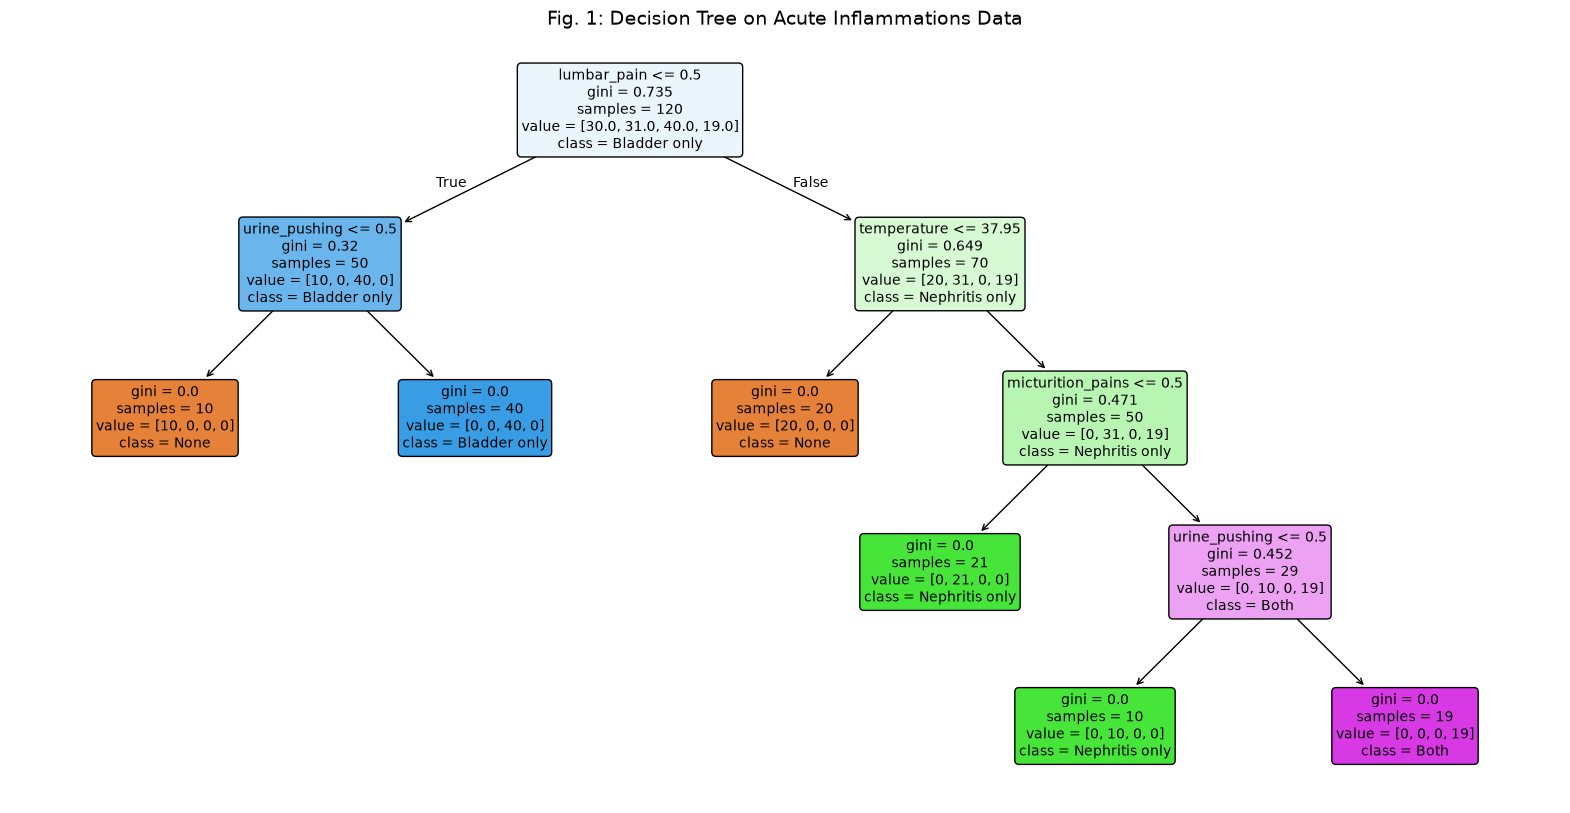

In [7]:
label_map = {'00': 'None', '01': 'Nephritis only', '10': 'Bladder only', '11': 'Both'}
class_names = [label_map[c] for c in tree_c.classes_]

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(tree_c, feature_names=feat, class_names=class_names,
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title('Fig. 1: Decision Tree on Acute Inflammations Data', fontsize=14)
plt.show()

**Interpretation:** The tree has depth 4, 5 splits and 6 leaves, with a training accuracy of 1.0.

- **lumbar_pain is the root:** it best separates nephritis from bladder inflammation.
  Patients without lumbar pain contain no nephritis cases (both "Nephritis only" and "Both" are 0),
  while patients with lumbar pain contain no "Bladder only" cases. It gives the largest Gini decrease.
- **Reading the paths:** urine pushing together with micturition pains is typical of bladder
  inflammation; lumbar pain with high temperature (> 37.95) is typical of nephritis.
  If a patient has lumbar pain, high temperature, urine pushing and micturition pains, they have both diseases.
- **Training accuracy of 1.0 does not mean good generalization.** A tree can always split the
  training data perfectly if it makes enough cuts, which may cause overfitting. Performance on new
  patients should be judged on test data, and the tree can be simplified by pruning (see 1(d)).

### (c) Convert the decision rules

In [8]:
# make the rule more readable
def describe(name, threshold, go_left):
    if name == 'temperature':
        return f"{name} <= {threshold:.2f}" if go_left else f"{name} > {threshold:.2f}"
    return f"{name} = {'no' if go_left else 'yes'}"

def get_rules(clf, feature_names, label_map):
    """Extract IF-THEN rules from a fitted decision tree (one rule per leaf)."""
    t = clf.tree_
    rules = []

    def recurse(node, conditions):
        # Base case: a leaf has no children (children_left == -1)
        if t.children_left[node] == -1:
            cls = clf.classes_[np.argmax(t.value[node])]
            rules.append((conditions, label_map[cls], t.n_node_samples[node]))
            return
        # Recursive step: go left (condition true) and right (condition false)
        name = feature_names[t.feature[node]]
        thr = t.threshold[node]
        recurse(t.children_left[node], conditions + [describe(name, thr, True)])
        recurse(t.children_right[node], conditions + [describe(name, thr, False)])

    recurse(0, [])
    return rules
    
rules = get_rules(tree_c, feat, label_map)
for i, (conds, cls, n) in enumerate(rules, start=1):
    print(f"Rule {i}: IF {' AND '.join(conds)} THEN {cls}  (samples = {n})")

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN None  (samples = 10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN Bladder only  (samples = 40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN None  (samples = 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN Nephritis only  (samples = 21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN Nephritis only  (samples = 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN Both  (samples = 19)


### (d)  cost-complexity pruning

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [10]:
# Get the pruning path

path = tree_c.cost_complexity_pruning_path(X,yc)
alphas = path.ccp_alphas
im = path.impurities

# cv to find best alpha
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

results = []

for a in alphas:
    tree_a  =  DecisionTreeClassifier(random_state =552, ccp_alpha = a )
    cv_scores = cross_val_score(tree_a, X, yc, cv=cv)
    tree_a.fit(X, yc)
    results.append({'alpha': a,
                    'leaves': tree_a.get_n_leaves(),
                    'depth': tree_a.get_depth(),
                    'train_acc': tree_a.score(X, yc),
                    'cv_acc_mean': cv_scores.mean(),
                    'cv_acc_std': cv_scores.std()})

res = pd.DataFrame(results)
res['impurity'] = im
res.round(4)

,alpha,leaves,depth,train_acc,cv_acc_mean,cv_acc_std,impurity
0,0.0000,6,4,1.0000,0.9917,0.0167,0.0000
1,0.0982,4,2,0.8417,0.8583,0.0500,0.1963
2,0.1333,3,2,0.7583,0.7667,0.0624,0.3297
3,0.1820,2,1,0.5917,0.6750,0.0667,0.5117
4,0.2229,1,0,0.3333,0.4833,0.1225,0.7346


**Observation on training and CV accuracy:** As α increases, both training accuracy and CV accuracy
decrease (Table above). Normally pruning lowers training accuracy but can raise CV accuracy
by reducing overfitting. That does not happen here: the full tree already reaches a CV accuracy of 0.99,
so it is not overfitting. The data set was built from expert rules and has no noise, so every split
captures a real pattern. Pruning therefore removes real information, and both accuracies drop together.

Chosen alpha: 0.0982
Leaves: 4 | Depth: 2 | Training accuracy: 0.8417 | CV accuracy: 0.8583


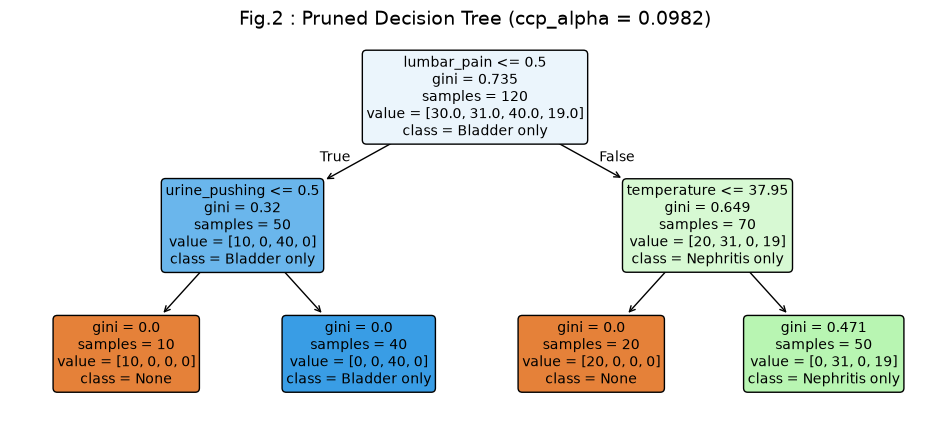

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN None  (samples = 10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN Bladder only  (samples = 40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN None  (samples = 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 THEN Nephritis only  (samples = 50)


In [11]:
# Choose the first pruned tree on the path (4 leaves)
chosen_idx = 1
chosen_alpha = res.loc[chosen_idx, 'alpha']

tree_pruned = DecisionTreeClassifier(random_state=552, ccp_alpha=chosen_alpha)
tree_pruned.fit(X, yc)
print(f'Chosen alpha: {chosen_alpha:.4f}')
print('Leaves:', tree_pruned.get_n_leaves(), '| Depth:', tree_pruned.get_depth(),
      '| Training accuracy:', round(tree_pruned.score(X, yc), 4),
      '| CV accuracy:', round(res.loc[chosen_idx, 'cv_acc_mean'], 4))

# Plot the pruned tree
class_names_p = [label_map[c] for c in tree_pruned.classes_]
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(tree_pruned, feature_names=feat, class_names=class_names_p,
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title(f'Fig.2 : Pruned Decision Tree (ccp_alpha = {chosen_alpha:.4f})', fontsize=14)
plt.show()

for i, (conds, cls, n) in enumerate(get_rules(tree_pruned, feat, label_map), start=1):
    print(f"Rule {i}: IF {' AND '.join(conds)} THEN {cls}  (samples = {n})")

**Conclusion:** Cross-validation alone favors the full tree (α = 0, CV accuracy 0.99), since the
noise-free data set causes no overfitting and every pruning step lowers accuracy.
Since this question asks for **high interpretability**, I choose the first pruned tree (**α = 0.0982**). It has 4 leaves and depth 2, and it only uses lumbar pain, temperature and urine pushing:

1. IF no lumbar pain AND no urine pushing THEN None
2. IF no lumbar pain AND urine pushing THEN Bladder only
3. IF lumbar pain AND temperature ≤ 37.95 THEN None
4. IF lumbar pain AND temperature > 37.95 THEN Nephritis only

**Trade-off:** CV accuracy drops from 0.99 to 0.86, and the tree can no longer predict "Both", so
19 patients with both diseases are labeled "Nephritis only" (bladder inflammation is missed).
Pruning further would drop CV accuracy to 0.77, so 4 leaves is the smallest tree that keeps reasonably high accuracy.

**Note:** **Keeping the full tree is also a reasonable choice I think**. It is already shallow (depth 4, 6 rules),
so it remains easy to interpret, and **in a medical setting a missed diagnosis usually costs more than
a slightly longer rule set**.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [12]:
with open('../data/communities.names') as f:
    crime_cols = [line.split()[1] for line in f if line.startswith('@attribute')]

print(len(crime_cols))
print(crime_cols[:6], '...', crime_cols[-1])

128
['state', 'county', 'community', 'communityname', 'fold', 'population'] ... ViolentCrimesPerPop


In [13]:
crime = pd.read_csv('../data/communities.data', header=None,
                    names=crime_cols, na_values='?')

print(crime.shape)
print(crime.isna().sum()[crime.isna().sum() > 0]) # missing value
crime.head()

(1994, 128)
county                  1174
community               1177
OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [14]:
# split test and train data

train = crime.iloc[:1495]
test = crime.iloc[1495:]
print("train", train.shape)
print("test", test.shape)

train (1495, 128)
test (499, 128)


### (b) Missing values

In [15]:
from sklearn.impute import SimpleImputer

In [16]:
#drop non-predictive cols

drop = ['state', 'county', 'community', 'communityname', 'fold']

yt = 'ViolentCrimesPerPop'

X_train = train.drop(columns = drop + [yt])
y_train = train[yt]
X_test = test.drop(columns = drop + [yt])
y_test = test[yt]

print("x_train", X_train.shape)
print("y_train", y_train.shape)
print("columns with missing values", (X_train.isna().sum() > 0).sum())

x_train (1495, 122)
y_train (1495,)
columns with missing values 23


In [17]:
# detect missing-value features distribution( for choosing the way of imputation)
miss_cols = X_train.columns[X_train.isna().sum() > 0]
X_train[miss_cols].agg(['mean', 'median']).T.round(3)

,mean,median
OtherPerCap,0.282,0.25
LemasSwornFT,0.075,0.02
LemasSwFTPerPop,0.215,0.18
LemasSwFTFieldOps,0.919,0.97
LemasSwFTFieldPerPop,0.245,0.21
LemasTotalReq,0.101,0.04
LemasTotReqPerPop,0.214,0.17
PolicReqPerOffic,0.345,0.30
PolicPerPop,0.215,0.18
RacialMatchCommPol,0.682,0.73


I use **median imputation** rather than the default mean, because many of these features are
skewed (e.g. `LemasSwornFT`: mean 0.075 vs. median 0.020; `LemasSwFTFieldOps`: mean 0.919 vs.
median 0.970), and the median is not pulled by extreme values in either direction.

In [18]:
# imputation for missing value ( use median)

imputer = SimpleImputer(strategy = "median")

X_train = pd.DataFrame(imputer.fit_transform(X_train),
                       columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test),
                      columns = X_test.columns, index = X_test.index)

print(X_train.isna().sum().sum(), '(train),', X_test.isna().sum().sum(), '(test)')

0 (train), 0 (test)


### (c) Plot a correlation matrix

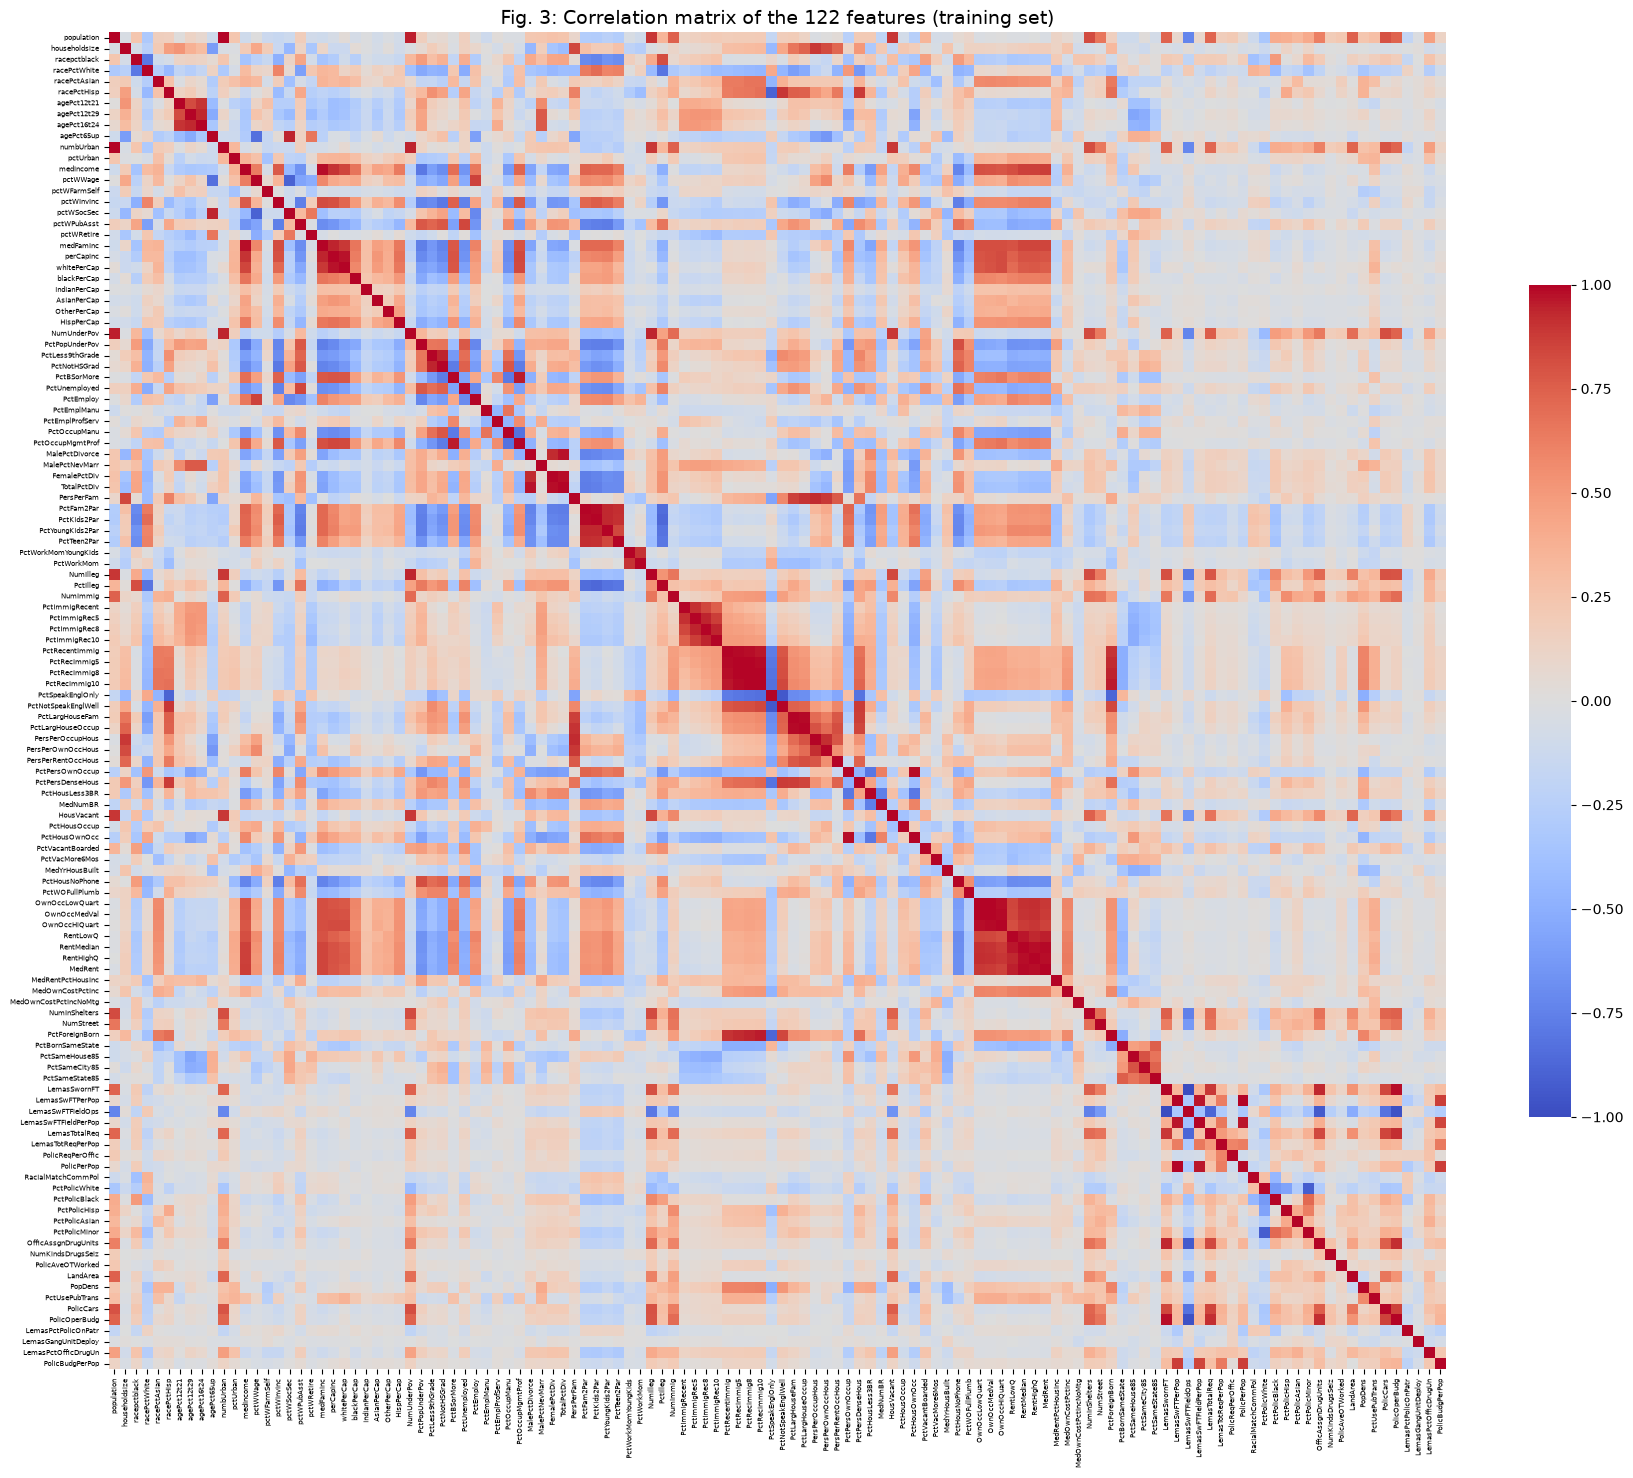

In [19]:
corr = X_train.corr()

fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={'shrink': 0.6}, ax=ax)
ax.tick_params(labelsize=5)
ax.set_title('Fig. 3: Correlation matrix of the 122 features (training set)', fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
# find most highly correlated feature pairs
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().dropna()

print('Number of feature pairs:', len(pairs))
print('Pairs with |r| > 0.9:', (pairs.abs() > 0.9).sum())
print('Pairs with |r| > 0.8:', (pairs.abs() > 0.8).sum())
pairs.abs().sort_values(ascending=False).head(10).round(3)

Number of feature pairs: 7381
Pairs with |r| > 0.9: 61
Pairs with |r| > 0.8: 156


LemasSwFTPerPop  PolicPerPop          1.000
PctRecImmig8     PctRecImmig10        0.996
OwnOccLowQuart   OwnOccMedVal         0.995
LemasSwornFT     LemasSwFTFieldOps    0.995
population       numbUrban            0.994
PctRecImmig5     PctRecImmig8         0.993
OwnOccMedVal     OwnOccHiQuart        0.992
PctRecentImmig   PctRecImmig5         0.989
RentMedian       MedRent              0.989
PctFam2Par       PctKids2Par          0.986
dtype: float64

**Observation:** The correlation matrix shows strong **multicollinearity**. Of the 7381
feature pairs, 61 have |r| > 0.9 and 156 have |r| > 0.8. The red blocks along the diagonal are
groups of features measuring the same concept in different ways: income (`medFamInc`, `perCapInc`),
family structure (`PctFam2Par`, `PctKids2Par`), recent immigration (`PctRecImmig5/8/10`),
housing value and rent (`OwnOcc*`, `Rent*`), and police (`Lemas*`). `LemasSwFTPerPop` and
`PolicPerPop` are identical.

This makes ordinary least squares coefficients unstable and hard to interpret, which motivates
Ridge, LASSO and PCR in parts (g)–(i).

### (d) Calculate the Coefficient of Variation CV

In [21]:
cv_feat = (X_train.std()/ X_train.mean()).sort_values(ascending = False)
cv_feat = cv_feat.rename('CV').to_frame()

print('Number of features:', len(cv_feat))
cv_feat.round(3)

Number of features: 122


,CV
PctPolicAsian,5.527
NumStreet,4.293
NumInShelters,3.471
NumIlleg,3.059
NumImmig,2.927
...,...
NumKindsDrugsSeiz,0.141
RacialMatchCommPol,0.130
PctPolicWhite,0.119
LemasPctPolicOnPatr,0.112


In [22]:
print('Top 12 features by CV:')
print( cv_feat.head(12).round(3))
print('\nBottom 5 features by CV:')
print(cv_feat.tail(5).round(3))

Top 12 features by CV:
                        CV
PctPolicAsian        5.527
NumStreet            4.293
NumInShelters        3.471
NumIlleg             3.059
NumImmig             2.927
LemasPctOfficDrugUn  2.553
NumUnderPov          2.342
LemasSwornFT         2.248
population           2.241
numbUrban            2.038
HousVacant           1.968
PolicOperBudg        1.646

Bottom 5 features by CV:
                        CV
NumKindsDrugsSeiz    0.141
RacialMatchCommPol   0.130
PctPolicWhite        0.119
LemasPctPolicOnPatr  0.112
LemasSwFTFieldOps    0.064


In [23]:
obs = train['PctPolicAsian'].dropna()
print('CV of PctPolicAsian on observed values only:', round(obs.std() / obs.mean(), 2))

corr_y = X_train.corrwith(y_train)
top_corr = corr_y.abs().sort_values(ascending=False).head(5).index
pd.DataFrame({'corr with target': corr_y[top_corr].round(3),
              'CV rank': [list(cv_feat.index).index(f) + 1 for f in top_corr]})

CV of PctPolicAsian on observed values only: 2.01


,corr with target,CV rank
PctIlleg,0.742,31
PctKids2Par,-0.741,102
PctFam2Par,-0.711,105
racePctWhite,-0.691,106
PctTeen2Par,-0.669,108


**Observation:** The highest CVs come from count features (`NumStreet`, `NumInShelters`, `NumIlleg`,
`population`, ...). Most communities are small, so these features have a mean close to 0, while a few
large cities have values near 1. A small mean and a relatively large standard deviation give a high CV.

`PctPolicAsian` ranks first (CV = 5.53) mainly because of imputation: 84% of its values were filled
with the median 0, which pulls the mean down. Its CV on the observed values alone is only 2.01.

A high CV does not mean a feature is important for prediction. The features most correlated with
`ViolentCrimesPerPop` (e.g. `PctIlleg`, `PctKids2Par`) have low CVs. Also, because the features are
normalized to [0, 1], CV depends on the arbitrary location of 0.

### (e) Scatter plots and box plots for highest CV features

In [24]:
k = int(np.floor(np.sqrt(128)))
top_feats = cv_feat.index[:k].tolist()
print(k)
print(top_feats)

11
['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


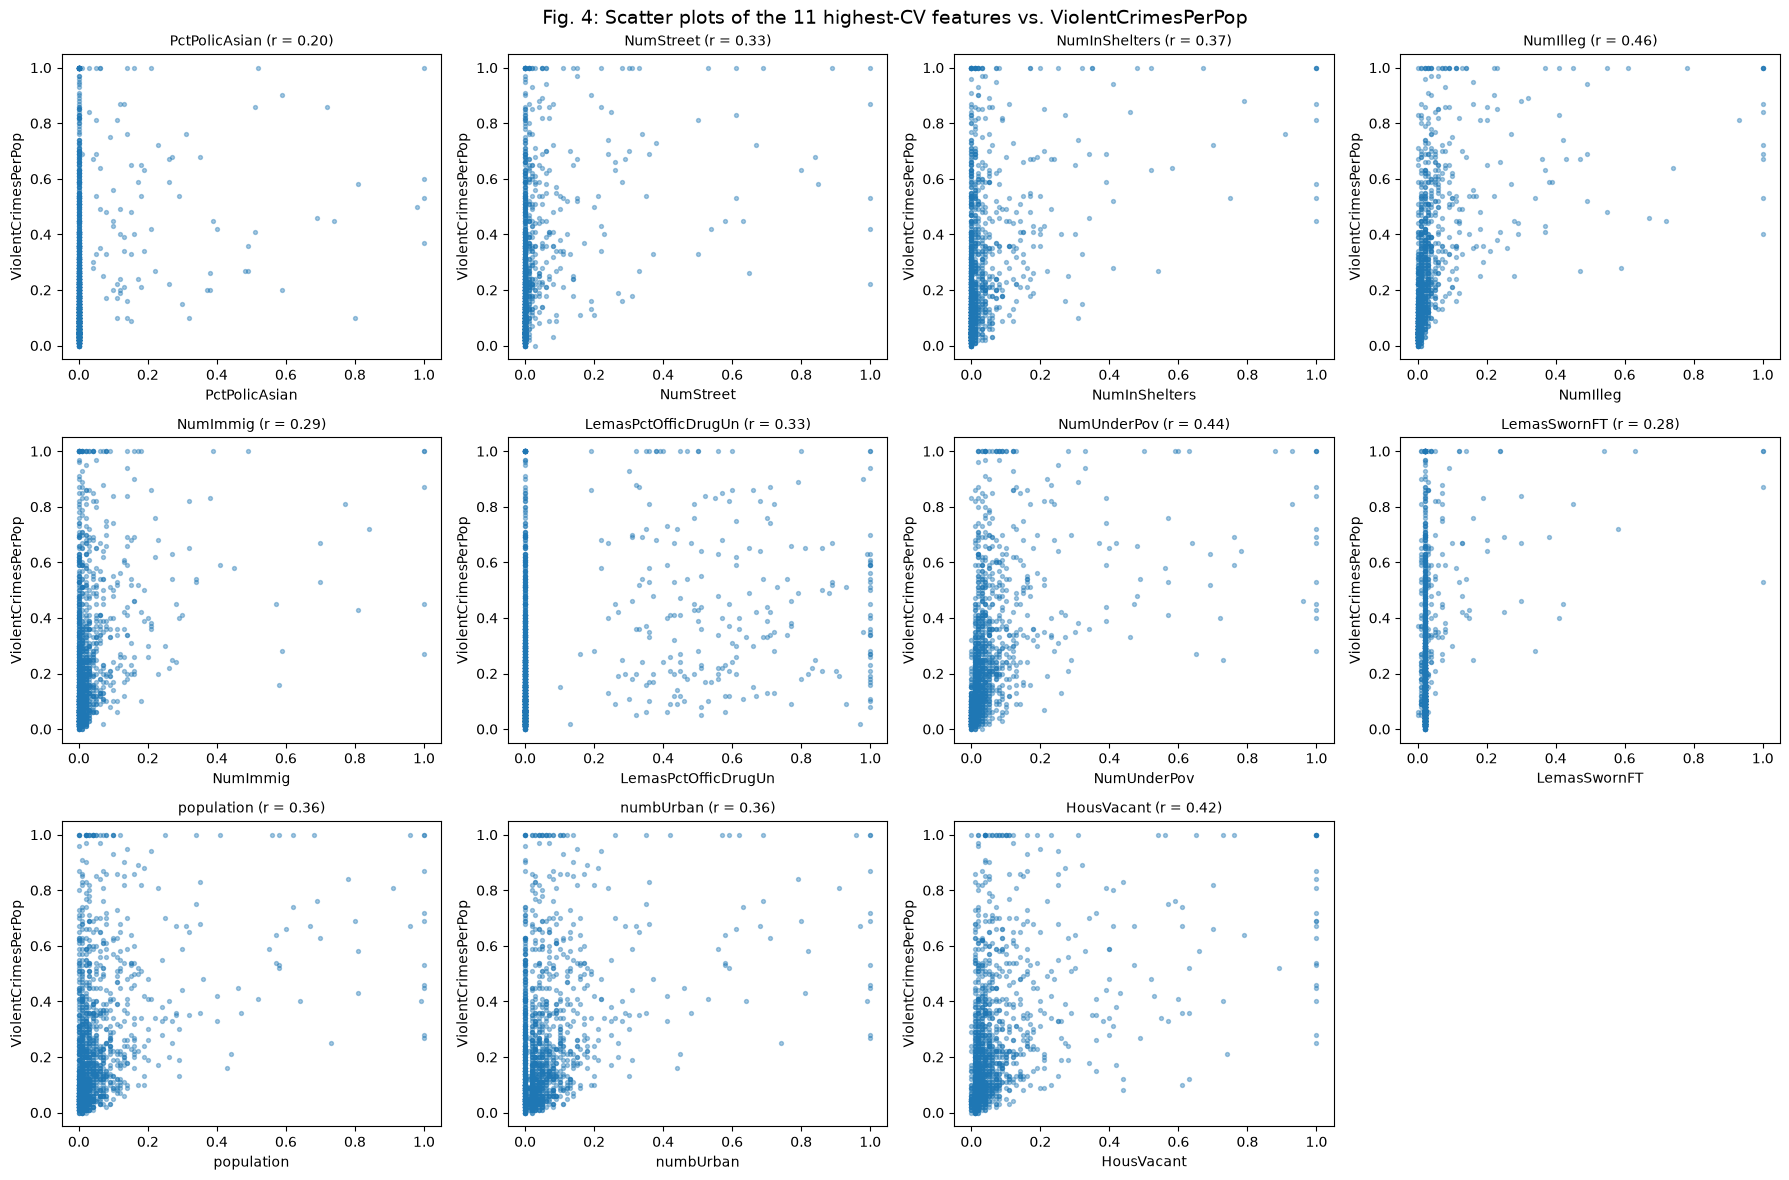

In [25]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, f in zip(axes, top_feats):
    ax.scatter(X_train[f], y_train, s=8, alpha=0.4)
    ax.set_xlabel(f)
    ax.set_ylabel('ViolentCrimesPerPop')
    ax.set_title(f'{f} (r = {X_train[f].corr(y_train):.2f})', fontsize=10)

for ax in axes[k:]:
    ax.remove()

fig.suptitle('Fig. 4: Scatter plots of the 11 highest-CV features vs. ViolentCrimesPerPop',
             fontsize=14)
plt.tight_layout()
plt.show()

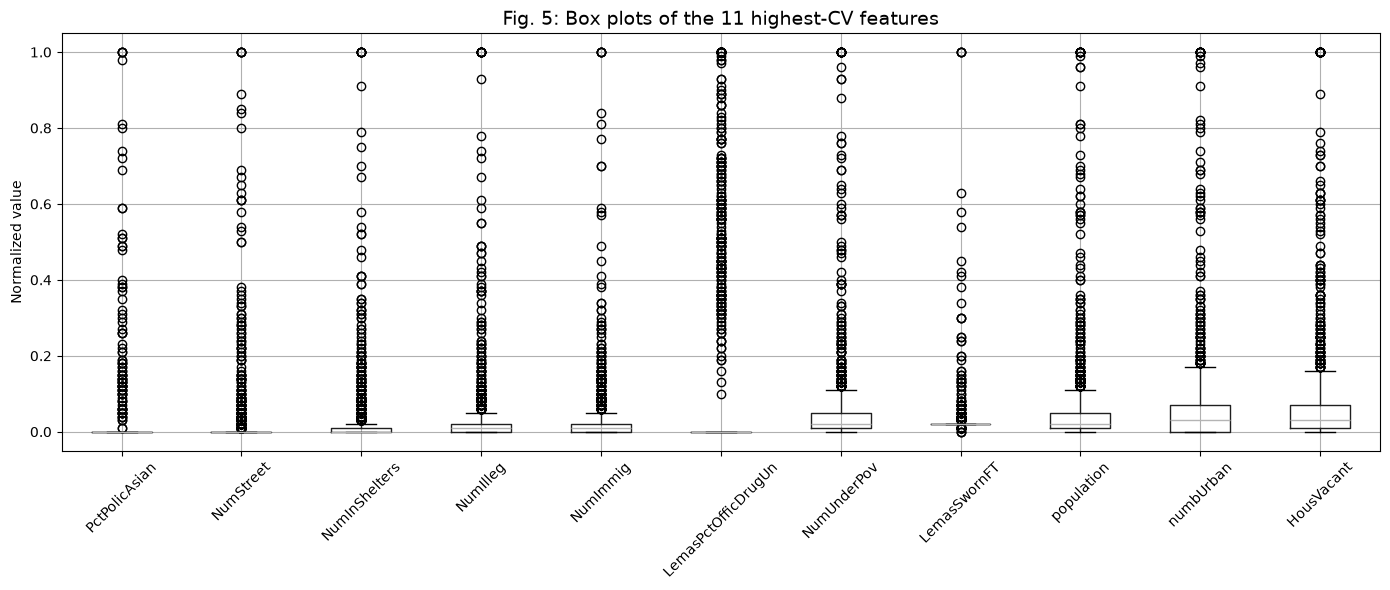

In [26]:
fig, ax = plt.subplots(figsize=(14, 6))
X_train[top_feats].boxplot(ax=ax, rot=45)
ax.set_ylabel('Normalized value')
ax.set_title('Fig. 5: Box plots of the 11 highest-CV features', fontsize=14)
plt.tight_layout()
plt.show()

**Observation:** Most of these features are concentrated near 0, with long right tails: in the box plots
the boxes collapse near 0 and most large values appear as outliers. In the scatter plots,
most points are squeezed into a narrow band at the left, so the relation with `ViolentCrimesPerPop`
is hard to see. The vertical columns for `PctPolicAsian` (x = 0) and `LemasSwornFT` (x ≈ 0.02) come
from median imputation; the one for `LemasPctOfficDrugUn` comes from real zeros.

**I think we can not conclude significance from the scatter plots alone**
1. Points overlap heavily near 0, so the relationship is hard to judge visually.
2. Significance is a statistical concept: it requires a hypothesis test (e.g. a t-test on a regression
   coefficient) and a p-value.
3. A scatter plot only shows the marginal relation between one feature and the target. In a model with
   122 correlated features , a feature that looks related on its own may add little once the
   others are included, e.g. `population` and `numbUrban` (r = 0.994).

### (f) Fit a linear model

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [28]:
ols = LinearRegression()
ols.fit(X_train, y_train)

y_train_pred = ols.predict(X_train)
y_test_pred = ols.predict(X_test)

ols_train_mse = mean_squared_error(y_train, y_train_pred)
ols_test_mse = mean_squared_error(y_test, y_test_pred)

print(f'train MSE: {ols_train_mse:.5f}')
print(f'test MSE:     {ols_test_mse:.5f}')
print(f'training R2:  {r2_score(y_train, y_train_pred):.4f}')
print(f'test R2:      {r2_score(y_test, y_test_pred):.4f}')

train MSE: 0.01629
test MSE:     0.01797
training R2:  0.7115
test R2:      0.6222


In [29]:
ols_coef = pd.Series(ols.coef_, index = X_train.columns)
print('Correlation of TotalPctDiv with target:', round(X_train['TotalPctDiv'].corr(y_train), 2))
ols_coef.abs().sort_values(ascending=False).head(10).round(3)

Correlation of TotalPctDiv with target: 0.56


PctPersOwnOccup         0.892
PctHousOwnOcc           0.773
TotalPctDiv             0.683
PolicOperBudg           0.548
MalePctDivorce          0.527
OwnOccMedVal            0.478
PersPerOccupHous        0.466
OwnOccLowQuart          0.398
LemasSwFTFieldPerPop    0.396
MedRent                 0.375
dtype: float64

**Result:** The test MSE of ordinary least squares is **0.01797** (test R² = 0.622).
The training MSE is 0.01629, so there is mild overfitting with 122 features.

### (g) Fit a ridge regression model

In [30]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, GridSearchCV

In [31]:
kf = KFold(n_splits=10, shuffle=True, random_state=552) # use 10 fold because we have a large sample data set
ridge_alphas = np.logspace(-3, 3, 61)

ridge_cv = GridSearchCV(Ridge(), param_grid={'alpha': ridge_alphas},
                        cv=kf, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train, y_train)

ridge_best_alpha = ridge_cv.best_params_['alpha']
ridge = ridge_cv.best_estimator_
ridge_test_mse = mean_squared_error(y_test, ridge.predict(X_test))

print(f'Best lambda (alpha): {ridge_best_alpha:.4f}')
print(f'cv mse at best lambda: {-ridge_cv.best_score_:.5f}')
print(f'train mse: {mean_squared_error(y_train, ridge.predict(X_train)):.5f}')
print(f'test mse:     {ridge_test_mse:.5f}')

Best lambda (alpha): 1.9953
cv mse at best lambda: 0.01904
train mse: 0.01692
test mse:     0.01753


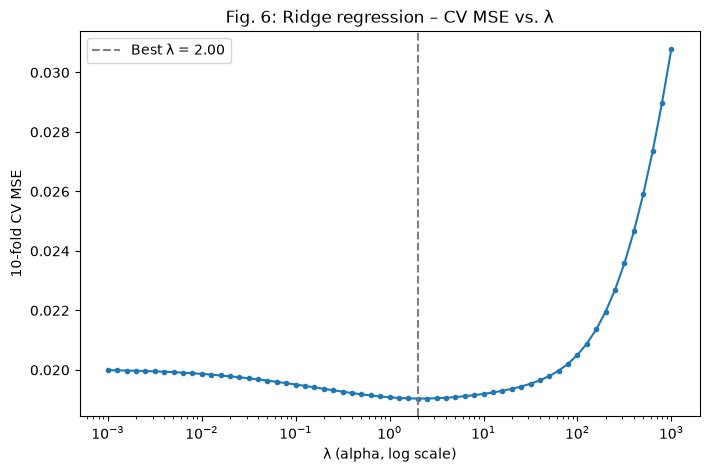

In [32]:
cv_mse = -ridge_cv.cv_results_['mean_test_score']

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ridge_alphas, cv_mse, marker='.')
ax.axvline(ridge_best_alpha, color='gray', linestyle='--',
           label=f'Best λ = {ridge_best_alpha:.2f}')
ax.set_xscale('log')
ax.set_xlabel('λ (alpha, log scale)')
ax.set_ylabel('10-fold CV MSE')
ax.set_title('Fig. 6: Ridge regression – CV MSE vs. λ')
ax.legend()
plt.show()

In [33]:
ridge_coef = pd.Series(ridge.coef_, index=X_train.columns)
compare = pd.DataFrame({'OLS': ols_coef, 'Ridge': ridge_coef})
print('Largest |coefficient|:  OLS =', round(ols_coef.abs().max(), 3),
      '| Ridge =', round(ridge_coef.abs().max(), 3))
compare.loc[['PctPersOwnOccup', 'PctHousOwnOcc', 'TotalPctDiv', 'MalePctDivorce',
             'OwnOccMedVal', 'OwnOccLowQuart']].round(3)

Largest |coefficient|:  OLS = 0.892 | Ridge = 0.222


,OLS,Ridge
PctPersOwnOccup,-0.892,-0.074
PctHousOwnOcc,0.773,0.015
TotalPctDiv,-0.683,-0.015
MalePctDivorce,0.527,0.124
OwnOccMedVal,0.478,0.017
OwnOccLowQuart,-0.398,-0.045


**Result:** 10-fold CV selects **λ = 2.00** (CV MSE = 0.01904, Fig. 6). The **test MSE of ridge
regression is 0.01753**, lower than OLS (0.01797), while its training MSE is slightly higher
(0.01692 vs. 0.01629): the penalty adds a little bias but reduces variance.

Ridge also stabilizes the coefficients. The largest |coefficient| drops from 0.892 (OLS) to 0.222,
and the large opposite-sign pairs caused by multicollinearity shrink to near zero

### (h) Fit a LASSO model

In [34]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [35]:
def fit_lasso(model, param_name):
    """Tune lambda by 10-fold CV, then return test MSE, best lambda and selected variables."""
    cv = GridSearchCV(model, {param_name: lasso_alphas}, cv=kf,
                      scoring='neg_mean_squared_error').fit(X_train, y_train)
    best = cv.best_estimator_
    lasso_step = best.named_steps['lasso'] if hasattr(best, 'named_steps') else best
    coef = pd.Series(lasso_step.coef_, index=X_train.columns)
    selected = coef[coef != 0].sort_values(key=abs, ascending=False)
    test_mse = mean_squared_error(y_test, best.predict(X_test))
    return test_mse, cv.best_params_[param_name], selected

lasso_alphas = np.logspace(-5, -1, 41)
lasso_test_mse, lasso_lam, lasso_sel = fit_lasso(Lasso(max_iter=50000), 'alpha')
lasso_std_test_mse, lasso_std_lam, lasso_std_sel = fit_lasso(
    make_pipeline(StandardScaler(), Lasso(max_iter=50000)), 'lasso__alpha')

pd.DataFrame({'Best λ': [lasso_lam, lasso_std_lam],
              'Test MSE': [lasso_test_mse, lasso_std_test_mse],
              '# selected': [len(lasso_sel), len(lasso_std_sel)]},
             index=['Original features', 'Standardized features']).round(6)

,Best λ,Test MSE,# selected
Original features,0.000079,0.017691,79
Standardized features,0.000631,0.017723,76


In [36]:
# Selected variables of both versions, side by side (NaN = not selected)
print('Selected in both versions:', len(set(lasso_sel.index) & set(lasso_std_sel.index)))
with pd.option_context('display.max_rows', None):
    display(pd.DataFrame({'Original': lasso_sel, 'Standardized': lasso_std_sel})
            .sort_values('Standardized', key=abs, ascending=False).round(4))

Selected in both versions: 75


,Original,Standardized
racepctblack,0.2699,0.0680
PctPersDenseHous,0.2399,0.0434
agePct12t29,-0.3246,-0.0433
PctKids2Par,-0.2015,-0.0406
RentLowQ,-0.1722,-0.0308
MedRent,0.1838,0.0305
PctPopUnderPov,-0.1614,-0.0294
PctEmploy,0.1786,0.0252
MalePctNevMarr,0.1753,0.0247
PctIlleg,0.0925,0.0239


**Result:** λ is chosen by 10-fold CV for both versions.

| Model | Best λ | Test MSE | # selected variables |
|---|---|---|---|
| LASSO (original features) | 0.000079 | **0.01769** | 79 of 122 |
| LASSO (standardized features) | 0.000631 | **0.01772** | 76 of 122 |

The selected variables of both versions are listed in the table above (NaN = not selected).
The most important ones, by standardized coefficient, are `racepctblack` (+), `PctPersDenseHous` (+),
`agePct12t29` (−), `PctKids2Par` (−), `RentLowQ` (−) and `MedRent` (+).

**Comparison of the two versions:** The test MSEs are almost identical, and 75 variables are selected
by both. Standardization matters little here because the features are already normalized to [0, 1]:
Standardization matters little here because the features are already normalized to [0, 1],
so the L1 penalty already treats them fairly evenly.

**Comparison with OLS and Ridge:** LASSO (0.01769) predicts as well as Ridge (0.01753) and better than
OLS (0.01797), while using only 79 of the 122 features. Among highly correlated pairs it usually keeps
only one feature (e.g. `PctKids2Par` instead of `PctFam2Par`, `PctRecImmig10` instead of `PctRecImmig8`),
which makes the model simpler and easier to interpret than Ridge.

### (i) Fit a PCR model

In [37]:
from sklearn.decomposition import PCA

In [38]:
# PCR = standardize -> PCA (keep M components) -> linear regression; choose M by 10-fold CV
pcr_cv = GridSearchCV(make_pipeline(StandardScaler(), PCA(), LinearRegression()),
                      param_grid={'pca__n_components': list(range(1, X_train.shape[1] + 1))},
                      cv=kf, scoring='neg_mean_squared_error')
pcr_cv.fit(X_train, y_train)

pcr_best_M = pcr_cv.best_params_['pca__n_components']
pcr_test_mse = mean_squared_error(y_test, pcr_cv.predict(X_test))

print(f'Best M: {pcr_best_M}')
print(f'CV MSE at best M: {-pcr_cv.best_score_:.5f}')
print(f'Test MSE: {pcr_test_mse:.5f}')

Best M: 97
CV MSE at best M: 0.01949
Test MSE: 0.01837


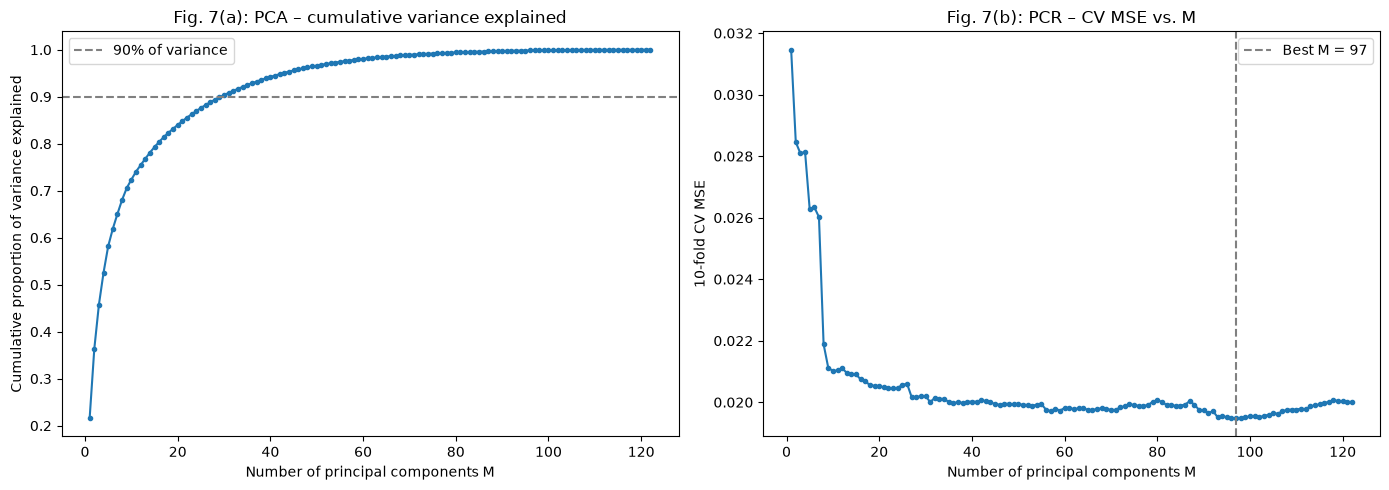

In [39]:
cv_mse_pcr = -pcr_cv.cv_results_['mean_test_score']
pca_full = make_pipeline(StandardScaler(), PCA()).fit(X_train).named_steps['pca']
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
Ms = np.arange(1, X_train.shape[1] + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(Ms, cum_var, marker='.')
axes[0].axhline(0.9, color='gray', linestyle='--', label='90% of variance')
axes[0].set_xlabel('Number of principal components M')
axes[0].set_ylabel('Cumulative proportion of variance explained')
axes[0].set_title('Fig. 7(a): PCA – cumulative variance explained')
axes[0].legend()

axes[1].plot(Ms, cv_mse_pcr, marker='.')
axes[1].axvline(pcr_best_M, color='gray', linestyle='--', label=f'Best M = {pcr_best_M}')
axes[1].set_xlabel('Number of principal components M')
axes[1].set_ylabel('10-fold CV MSE')
axes[1].set_title('Fig. 7(b): PCR – CV MSE vs. M')
axes[1].legend()

plt.tight_layout()
plt.show()

**Result:** 10-fold CV selects **M = 97** principal components (CV MSE = 0.01949, Fig. 7(b)).
The **test MSE of PCR is 0.01837**, the highest of all models so far (OLS 0.01797, Ridge 0.01753,
LASSO 0.01769).

**Discussion:**
- The first 30 components already explain 90% of the variance (Fig. 7(a)), but CV still needs many more.
  PCA is unsupervised: it ranks directions by the variance of X, not by their relation to the target.
  For example, adding the 8th component alone drops the CV MSE from about 0.026 to 0.022, although it
  explains only a few percent of the variance.
- The CV curve is almost flat for M > 20 (between about 0.0195 and 0.0205), so the choice of M = 97 is
  not very reliable: a much smaller M (e.g. about 30) performs almost as well and gives a simpler model.
  With M = 122, PCR equals OLS, so on this data set PCR brings no real gain over OLS.


### (j) Fit a boosting tree

In [40]:
from xgboost import XGBRegressor

In [41]:
# other hyperparameters are fixed; only the L1 penalty reg_alpha is tuned by 10-fold CV
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                   subsample=0.8, colsample_bytree=0.8, random_state=552, n_jobs=-1)
xgb_alphas = np.logspace(-4, 1, 11)

xgb_cv = GridSearchCV(xgb, param_grid={'reg_alpha': xgb_alphas},
                      cv=kf, scoring='neg_mean_squared_error')
xgb_cv.fit(X_train, y_train)

xgb_best_alpha = xgb_cv.best_params_['reg_alpha']
xgb_test_mse = mean_squared_error(y_test, xgb_cv.predict(X_test))

print(f'Best α (reg_alpha): {xgb_best_alpha:.4f}')
print(f'CV MSE at best α: {-xgb_cv.best_score_:.5f}')
print(f'Training MSE: {mean_squared_error(y_train, xgb_cv.predict(X_train)):.5f}')
print(f'Test MSE:     {xgb_test_mse:.5f}')

Best α (reg_alpha): 3.1623
CV MSE at best α: 0.01898
Training MSE: 0.00974
Test MSE:     0.01570


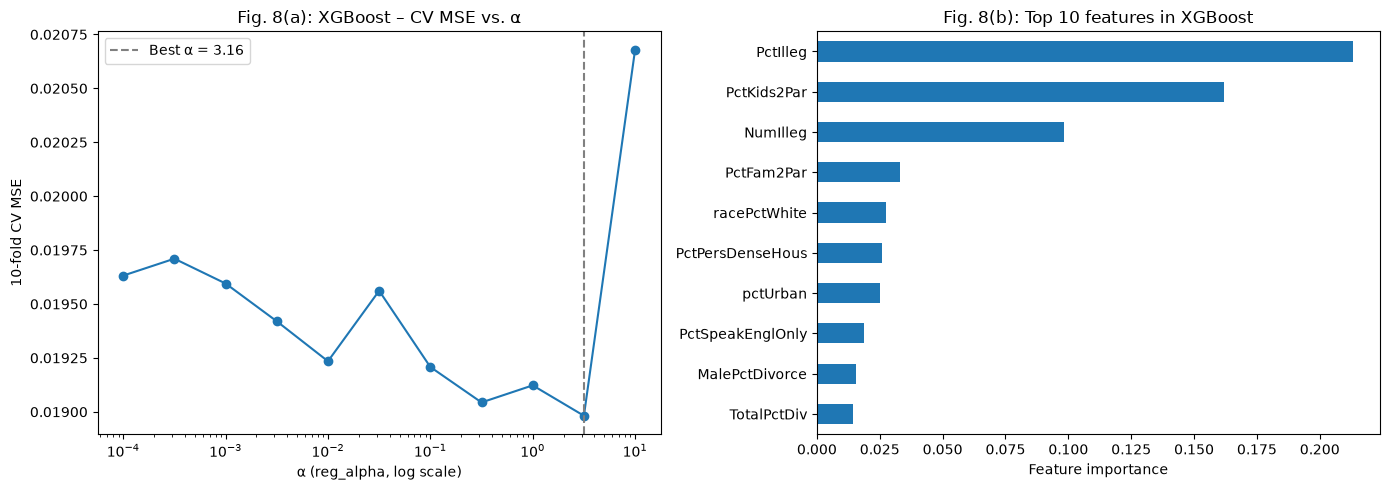

In [42]:
xgb_cv_mse = -xgb_cv.cv_results_['mean_test_score']
xgb_importance = pd.Series(xgb_cv.best_estimator_.feature_importances_,
                           index=X_train.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(xgb_alphas, xgb_cv_mse, marker='o')
axes[0].axvline(xgb_best_alpha, color='gray', linestyle='--', label=f'Best α = {xgb_best_alpha:.2f}')
axes[0].set_xscale('log')
axes[0].set_xlabel('α (reg_alpha, log scale)')
axes[0].set_ylabel('10-fold CV MSE')
axes[0].set_title('Fig. 8(a): XGBoost – CV MSE vs. α')
axes[0].legend()

xgb_importance.head(10)[::-1].plot.barh(ax=axes[1])
axes[1].set_xlabel('Feature importance')
axes[1].set_title('Fig. 8(b): Top 10 features in XGBoost')

plt.tight_layout()
plt.show()

**Result:** With the other hyperparameters fixed (500 trees, learning rate 0.05, max depth 3,
subsample 0.8, colsample_bytree 0.8), 10-fold CV selects **α = 3.16** (CV MSE = 0.01898, Fig. 8(a)).
The **test MSE of the L1-penalized boosting tree is 0.01570**, the lowest of all models.

**Discussion:**
- Boosting fits many small trees one after another, each correcting the remaining errors, so it can
  capture non-linear effects and interactions that the linear models (OLS, Ridge, LASSO, PCR) cannot.
- The training MSE (0.00974) is much lower than the test MSE, so the model fits the training data
  more closely than the linear models. The L1 penalty limits this: CV MSE is fairly flat for small α,
  and rises sharply at α = 10, where the penalty is too strong.
- The most important features (Fig. 8(b)) are `PctIlleg`, `PctKids2Par` and `NumIlleg`, followed by
  `PctFam2Par` and `racePctWhite`. They match the features most correlated with the target, and none
  of the highest-CV features from (e) except `NumIlleg` appears in the top 10.

In [43]:
summary = pd.DataFrame({
    'Model': ['OLS', 'Ridge', 'LASSO (original)', 'LASSO (standardized)', 'PCR', 'XGBoost (L1)'],
    'Tuning parameter': ['–', f'λ = {ridge_best_alpha:.3f}', f'λ = {lasso_lam:.6f}',
                         f'λ = {lasso_std_lam:.6f}', f'M = {pcr_best_M}', f'α = {xgb_best_alpha:.3f}'],
    'Test MSE': [ols_test_mse, ridge_test_mse, lasso_test_mse,
                 lasso_std_test_mse, pcr_test_mse, xgb_test_mse]
}).set_index('Model')
summary['Test MSE'] = summary['Test MSE'].round(5)
summary.sort_values('Test MSE')

,Tuning parameter,Test MSE
Model,,
XGBoost (L1),α = 3.162,0.01570
Ridge,λ = 1.995,0.01753
LASSO (original),λ = 0.000079,0.01769
LASSO (standardized),λ = 0.000631,0.01772
OLS,–,0.01797
PCR,M = 97,0.01837


**Conclusion:** The L1-penalized boosting tree has the lowest test MSE, because it can model non-linear
relations and interactions. Among the linear models, Ridge and LASSO improve slightly on OLS by
handling multicollinearity; LASSO also reduces the model to about 79 features, which makes it easier
to interpret. PCR does not improve on OLS here, because the high-variance principal components are
not necessarily the ones most related to violent crime.

**References**
   1. UCI Machine Learning Repository – Acute Inflammations: https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations
   2. UCI Machine Learning Repository – Communities and Crime: https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime
   3. KDnuggets – Simplifying Decision Tree Interpretability with Python & Scikit-learn: https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
   4. scikit-learn documentation: https://scikit-learn.org/stable/
   5. XGBoost documentation: https://xgboost.readthedocs.io/
   6. James, Witten, Hastie, Tibshirani – An Introduction to Statistical Learning (ISLR)